In [6]:
import numpy as np
import matplotlib.pyplot as plt
from numba import njit, prange
import pandas as pd

## Parte inicial

In [7]:
# Función donde se calcula la posición y velocidad en un instante de tiempo
@njit(parallel=True)
def step(pos, vel, f, K, L, R, dt, sqrtdt, cell_size, ncell, head, nextp):

    N = pos.shape[0]

    # Reiniciar celdas
    head[:]=-1

    # Construir celdas

    # Construir cell list
    for i in range(N):
        cx = int(pos[i,0] / cell_size)
        cy = int(pos[i,1] / cell_size)

        if cx >= ncell:
            cx = ncell-1
        if cy >= ncell:
            cy = ncell-1

        cell_id = cx + cy*ncell
        nextp[i] = head[cell_id]
        head[cell_id] = i

    # Buscar vecinos y calcular fi
    for i in prange(N):

        pix = pos[i,0]
        piy = pos[i,1]

        cx = int(pix / cell_size)
        cy = int(piy / cell_size)

        fix = 0
        fiy = 0

        for dx in (-1,0,1):
            for dy in (-1,0,1):

                nx = cx + dx
                ny = cy + dy

                if nx < 0:
                    nx += ncell
                elif nx >= ncell:
                    nx -= ncell

                if ny < 0:
                    ny += ncell
                elif ny >= ncell:
                    ny -= ncell


                cell_id = nx + ny*ncell

                j = head[cell_id]
                while j != -1:

                    dxij = pos[j,0] - pix
                    dyij = pos[j,1] - piy

                    if dxij > 0.5*L:
                      dxij -= L
                    elif dxij < -0.5*L:
                      dxij += L

                    if dyij > 0.5*L:
                      dyij -= L
                    elif dyij < -0.5*L:
                      dyij += L

                    #LO SIGUIENTE ELIMINA LA DIVERGENCIA, PERO NO GARANTIZA LA ESTABILIDAD
                    #DE LA INTEGRACIÓN
                    
                   # Fuerza inversa al cuadrado suavizada
                    dist2 = dxij*dxij + dyij*dyij

                    if 0.0 < dist2 < R*R:
                        a = 0.2  # Longitud de suavizado
                        r2_soft = dist2 + a*a

                        # Fuerza tipo 1/r^2
                        mag = K / (r2_soft * np.sqrt(r2_soft))

                        # Corte suave en R
                        cutoff = (1.0 - dist2/(R*R))**2
                        mag *= cutoff
                        fix += dxij * mag
                        fiy += dyij * mag

        f[i,0] = fix
        f[i,1] = fiy


    # Actualización fuerza, velocidad, posición
    for i in prange(N):
        vix = vel[i,0]
        viy = vel[i,1]

        fix = f[i,0]
        fiy = f[i,1]

        # generar ruido
        rx=np.random.normal(0,1) * sqrtdt
        ry=np.random.normal(0,1) * sqrtdt

        # Calcular velocidad
        vel[i,0] = vix + (fix - vix) * dt + rx
        vel[i,1] = viy + (fiy - viy) * dt + ry


        # Actualizar posiciones
        pos[i,0] += vel[i,0] * dt
        pos[i,1] += vel[i,1] * dt


        # Condiciones periódicas
        if pos[i,0] >= L:
            pos[i,0] -= L
        elif pos[i,0] < 0:
            pos[i,0] += L

        if pos[i,1] >= L:
            pos[i,1] -= L
        elif pos[i,1] < 0:
            pos[i,1] += L


    # Parámetro de orden
    sumvx = 0
    sumvy = 0

    for i in range(N):
        vx_f = vel[i,0]
        vy_f = vel[i,1]
        mag = np.sqrt(vx_f*vx_f + vy_f*vy_f) + 1e-8
        sumvx += vx_f/mag
        sumvy += vy_f/mag


    return np.sqrt(sumvx*sumvx + sumvy*sumvy) / N

In [8]:
# Función donde se calcula la posición y la velocidad para todos los tiempos
def sim(N,L, K, R, dt, t_relax, t_avg):

  # Inicializar parámetros celdas
  cell_size = R
  ncell = int(L / cell_size)
  head = np.empty(ncell*ncell, dtype=np.int64)
  nextp = np.empty(N, dtype=np.int64)

  # Incializar arrays parámetros fuerza, posición, velocidad
  pos = np.random.uniform(0, L, (N,2))
  vel = np.random.normal(loc=0, scale=1/np.sqrt(2), size=(N,2))
  t_total = t_relax + t_avg
  A = np.zeros(t_total)   # Párametro de orden
  f=np.zeros((N,2))
  sqrtdt = np.sqrt(dt)

  # Correr step para todos los tiempos
  for t in range(t_total):
      A[t] = step(pos, vel, f, K, L, R, dt, sqrtdt, cell_size, ncell, head, nextp)

  return A

## Pruebas

In [9]:
# Definición parámetros
dt = 0.01
L = 20
rho = 1
N = int(rho*L**2)
R = 1
K = 0
t_relax = 10000
t_avg = 10000
t_total = t_relax + t_avg

In [ ]:
# Correr simulación
A = sim(N,L, K, R, dt, t_relax, t_avg)

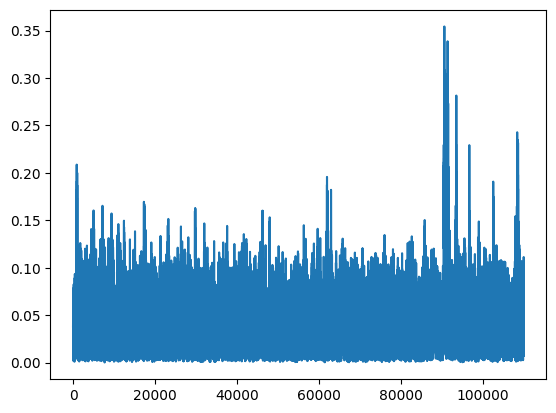

In [ ]:
# Graficar parámetro de orden
t = np.arange(t_total)
plt.plot(t,A)
plt.show()

In [ ]:
#Análisis de la serie temporal para la medicion del parametro de orden
time_axis = np.arange(len(A)) * dt

phi_eq = np.mean(A[t_relax:])
phi_std = np.std(A[t_relax:])

print("Orden promedio:", phi_eq)
print("Fluctuación del orden:", phi_std)

plt.plot(time_axis, A)
plt.axvline(t_relax * dt, linestyle="--",label="Inicio de medición")
plt.xlabel("Tiempo físico")
plt.ylabel("Parámetro de orden")
plt.legend()
plt.show()

In [ ]:
#TIEMPO DE EQUILIBRIO
#Valores exploratorios.
def estimate_equilibrium_time(A, dt, window=500,tolerance=0.03,consecutive=4):

    stable = 0

    for i in range(2*window, len(A), window):

        previous = np.mean(A[i-2*window:i-window])
        current = np.mean(A[i-window:i])

        if abs(current - previous) < tolerance:
            stable += 1
        else:
            stable = 0

        if stable >= consecutive:
            return i * dt

    return np.nan

In [ ]:
t_eq = estimate_equilibrium_time(A, dt)
print("Tiempo estimado de equilibrio:", t_eq)